# Novelty detection and threshold cost

**Question:** At the preregistered reconstruction threshold, what sensitivity and false-alarm rates does the OOD detector attain?
**Level 2 — Applied analysis**  
**Prerequisites:** Level 1 and arrays/logarithms; 35 min.

## Objectives

Rebuild the frozen CNN benchmark on exact held-out observations, then quantify misses from the fixed autoencoder threshold on the declared OOD cohort.

## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Data

Training ledger stores splits, normalized test errors, model metrics and a separately evaluated OOD control.

## Method

Novelty detection uses a score threshold fixed by a calibration policy. Sensitivity is TP/(TP+FN), specificity TN/(TN+FP); high specificity can coexist with zero OOD detection. The saved OOD evaluation has 160 calibration cases, 80 OOD, TP=0, FN=80, FP=3, TN=157. Recompute and plot all confusion counts and both rates instead of reporting accuracy alone. Do not retune on OOD labels. This is a negative result for the declared OOD set and threshold, not proof that all anomalies are undetectable. Interpret against the generator and exact split; production use would require externally representative, independently held-out domains and calibrated operating costs.

The test protocol reconstructs the recorded forward geometry, realization order, noise stream and target normalization before scoring. CNN output is a depth-integrated column, so its physical error cannot resolve vertical body position. The autoencoder threshold comes only from in-distribution calibration; OOD labels report consequences and must not retune it.

### What the held-out computation establishes

The test pipeline reconstructs the exact data-generating protocol rather than sampling a convenient miniature. Complete volumes use disjoint seeds for train, validation and test; their observations come from the same gravity sensitivity operator. The noise generator is advanced through the earlier partitions before the test draw, and the resulting array hash must match the persisted receipt. That check binds the forward geometry, realization order, normalization and noise stream to the published evaluation. A mismatch should stop scoring rather than be “fixed” by adjusting seeds until averages look similar.

The CNN output is a depth-integrated density contrast on a 2D grid. Summing the synthetic 3D target along depth and multiplying by vertical cell spacing yields the physical column target. The squared error therefore has units of integrated density squared. It cannot assess the vertical position of bodies or distinguish different 3D structures with the same column integral. A strong score on this target is not evidence of a uniquely recovered earth model.

Novelty detection uses the autoencoder’s normalized reconstruction error and an in-distribution calibration threshold fixed before OOD labels are inspected. Its false negatives show that low reconstruction error does not guarantee familiar geology. The score distributions overlap and AUC is below one half for this declared cohort. Changing the threshold after seeing OOD outcomes would invalidate the preregistered test; report the cost curve as a diagnostic, not a post-hoc repair.

## Results

**Answer:** CNN inference reproduces all 160 held-out errors (normalized MSE 0.00472348; physical MSE 755.757 versus weighted L2 1441.328). At threshold 0.0690652, TP/FN/FP/TN = 0/80/3/157.

## Summary

The fixed threshold misses all 80 declared OOD cases and produces three false alarms among 160 in-distribution test cases. This negative result applies to this generator and cost policy, not every anomaly domain; external representative cohorts remain necessary.

## References

- Cockett et al. (2018), SimPEG framework, *Geophysical Journal International*, https://doi.org/10.1093/gji/ggy423. Repository framework context, not the measured held-out result.
- AI4EPS PhaseNet repository: https://github.com/AI4EPS/PhaseNet. Adjacent phase-picking project listed in repository method metadata; not used by this gravity inference.
- LANL OpenFWI: https://github.com/lanl/OpenFWI. Seismic benchmark context listed by repository metadata; not an input to this experiment.


### Diagnostic 1

Inspect the committed case record and provenance.

In [1]:
# Initialize the notebook imports and locate repository inputs for the held-out lesson.
from pathlib import Path
from importlib.metadata import version
import numpy as np
import json
import sys
import torch
import hashlib
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir()
)


### Recompute detector rates

The confusion counts expose both missed OOD cases and false alarms on held-out in-distribution cases. Recompute sensitivity and specificity from those counts so the reported operating point can be checked independently of the plotted scores. These rates describe this fixed benchmark and do not establish a field operating threshold.

In [2]:
# Recompute sensitivity and specificity from the fixed receipt counts.
# Recompute novelty detector rates from the persisted confusion counts.
import json
from pathlib import Path

d = json.loads((root / "data/derived/v2/models/training.json").read_text(encoding="utf-8"))
e = d["novelty_evaluation"]
tp, fn, fp, tn = [e[k] for k in ("true_positive", "false_negative", "false_positive", "true_negative")]
sens = tp / (tp + fn)
spec = tn / (tn + fp)


### Load both frozen networks and the exact gravity forward operator before rebuilding held-out observations. The CNN predicts depth-integrated density, while the autoencoder produces a reconstruction score for novelty diagnostics. The checkpoints are fixed artifacts; the cells that follow run inference and compare it with the ledger rather than fitting new weights.

Cargue ambas redes congeladas y el operador gravimétrico exacto antes de reconstruir observaciones de prueba. La CNN predice densidad integrada en profundidad y el autoencoder produce una puntuación de reconstrucción para diagnosticar novedad. Los checkpoints son artefactos fijos; las celdas siguientes ejecutan inferencia y la comparan con el registro, sin ajustar pesos nuevos.

In [3]:
print(
    "calibration/OOD",
    e["calibration_count"],
    e["ood_count"],
    "threshold",
    d["novelty_threshold"],
    "TP FN FP TN",
    tp,
    fn,
    fp,
    tn,
    "sensitivity",
    sens,
    "specificity",
    spec,
    "AUC",
    e.get("roc_auc"),
)
# Load the committed trained bundle and forward operator used by this experiment.
import sys, torch, hashlib

sys.path.insert(0, str(root / "data-pipeline"))
import geology, learning, potential

cnn_model, ae_model, training_meta = learning.load_bundle(root / "data/derived/v2/models")
mesh_real, _, G_real, _ = potential.operators()


calibration/OOD 160 80 threshold 0.0690651684999466 TP FN FP TN 0 80 3 157 sensitivity 0.0 specificity 0.98125 AUC 0.361953125


### Diagnostic 2

Compute the declared comparison and plot it with physical units.

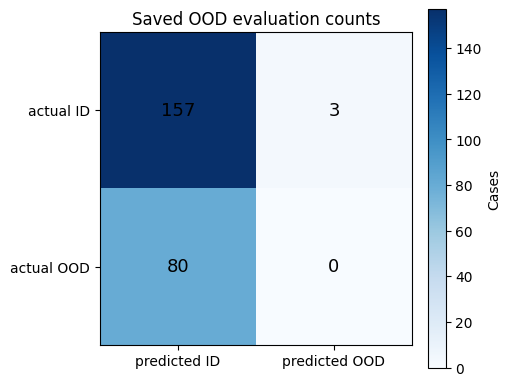

Sensitivity 0.0 specificity 0.98125 AUC 0.361953125


In [4]:
# Show all confusion counts so zero sensitivity cannot be hidden by high specificity.
import matplotlib.pyplot as plt

mat = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
im = ax.imshow(mat, cmap="Blues")
ax.set(
    xticks=[0, 1],
    xticklabels=["predicted ID", "predicted OOD"],
    yticks=[0, 1],
    yticklabels=["actual ID", "actual OOD"],
    title="Saved OOD evaluation counts",
)
for (i, j), v in np.ndenumerate(mat):
    ax.text(j, i, str(v), ha="center", va="center", fontsize=13)
fig.colorbar(im, ax=ax, label="Cases")
plt.show()
print("Sensitivity", sens, "specificity", spec, "AUC", e.get("roc_auc"))


### Experiment: threshold policy versus OOD consequences

The saved rule chooses the 99th percentile of **in-distribution calibration reconstruction errors** before examining the OOD set. Recompute consequences at the 90th, 95th and 99th calibration percentiles. For each threshold, report calibration false-alarm fraction and OOD sensitivity, but do not pick a threshold using OOD labels. This is a controlled operating-point analysis of the saved score arrays, not a new detector or a claim of representative geology. A high true-negative count can hide near-zero OOD sensitivity; state both rates and sample sizes.

In [5]:
# Recompute sensitivity and specificity from the fixed receipt counts.
# Execute the documented experiment with the repository evidence.
cal = np.asarray(e["calibration_errors"], float)
ood = np.asarray(e["ood_test_errors"], float)
assert len(cal) == e["calibration_count"] and len(ood) == e["ood_count"]
print("threshold quantile | threshold | calibration false alarms | OOD sensitivity (evaluation only)")
operating = []
for q in (0.90, 0.95, 0.99):
    threshold = float(np.quantile(cal, q))
    fpr = float(np.mean(cal > threshold))
    tpr = float(np.mean(ood > threshold))
    operating.append((q, threshold, fpr, tpr))
    print(f"{q:.0%} | {threshold:.6g} | {fpr:.3f} | {tpr:.3f}")
print(
    ("The 99th-percentile row is the preregistered ledger policy; "
     "OOD rates describe consequences, not threshold selection.")
)


threshold quantile | threshold | calibration false alarms | OOD sensitivity (evaluation only)
90% | 0.0202868 | 0.100 | 0.013
95% | 0.0463008 | 0.050 | 0.000
99% | 0.0690652 | 0.013 | 0.000
The 99th-percentile row is the preregistered ledger policy; OOD rates describe consequences, not threshold selection.


### Load trained model and forward geometry

The checkpoint is loaded from the committed training bundle, whose SHA-256 is checked by the loader. The forward operator and architecture must match the ledger. This is the actual trained model, not an untrained demonstration network.


In [6]:
# Check the loaded checkpoint identity and the physical forward dimensions.
cnn_sha = training_meta["models"]["cnn"]["sha256"]
print("CNN checkpoint", cnn_sha, "survey", training_meta["survey_shape"], "G", G_real.shape)


CNN checkpoint efdd5d4661ddadfeeeb6709eb42336b0cd91ade25548f119c1fbd3d6698c3125 survey [32, 32] G (1024, 10752)


### Rebuild the held-out test inputs

The benchmark uses complete realizations and the test seed recorded in the ledger. Rebuilding those exact targets and forward observations makes the inference input auditable. These are synthetic held-out cases, not field measurements.


In [7]:
# Regenerate the exact 160 test volumes and gravity observations from the ledger seed.
test_models = learning.generate(mesh_real.cell_centers, 160, training_meta["seeds"][2])
test_clean = test_models @ G_real.T
print("test models and clean observations", test_models.shape, test_clean.shape)


test models and clean observations (160, 10752) (160, 1024)


### Verify the benchmark noise realization

Training, validation and test noise share a single seeded generator stream, so the stream must advance through earlier partitions before reproducing test noise. The byte hash check prevents a merely similar reconstruction from being called the actual benchmark input.


In [8]:
# Advance the documented noise stream through train and validation before test.
noise_rng = np.random.default_rng(5001)
noise_rng.normal(0, 0.02 * training_meta["input_scale"], (800, G_real.shape[0]))
noise_rng.normal(0, 0.02 * training_meta["input_scale"], (160, G_real.shape[0]))
test_noise = noise_rng.normal(0, 0.02 * training_meta["input_scale"], test_clean.shape)
test_input = test_clean + test_noise
test_sha = hashlib.sha256(test_input.astype("<f8").tobytes()).hexdigest()
assert test_sha == training_meta["comparison"]["noisy_test_sha256"]
print("held-out input SHA-256 verified", test_sha)


held-out input SHA-256 verified 75fee10c9c19cff26ae51a02258ddd24c1958bf812c8b445abb3881e35b29940


### Run held-out CNN inference

The frozen CNN maps normalized gravity observations to a 2D depth-integrated density target. Summing the 3D synthetic truth over depth creates the matching target. It is not a 3D inverse and the test cases do not update weights.


In [9]:
# Infer the depth-integrated density target on the exact noisy held-out observations.
from geology import VOLUME_SHAPE, VOLUME_SPACING

x_test = torch.as_tensor(
    test_input / training_meta["input_scale"], dtype=torch.float32, device=next(cnn_model.parameters()).device
).reshape(-1, 1, *training_meta["survey_shape"])
y_test = test_models.reshape(-1, *VOLUME_SHAPE).sum(1) * VOLUME_SPACING[2] / training_meta["target_scale"]
with torch.no_grad():
    pred_test = cnn_model(x_test).cpu().numpy()
cnn_errors = np.mean((pred_test - y_test) ** 2, axis=(1, 2))
print("inferred cases", len(cnn_errors), "mean normalized MSE", float(cnn_errors.mean()))


inferred cases 160 mean normalized MSE 0.004723478481682726


### Compare inference to the receipt

Per-case errors are returned to physical squared units and matched against the committed ledger. Agreement verifies model loading, normalization, ordering and test inputs together. The weighted L2 and CNN predictions use identical observations; the comparison remains conditional on this synthetic generator.


In [10]:
# Reconstruct physical-unit paired CNN errors and verify each recorded test case.
cnn_mse_physical = cnn_errors * training_meta["target_scale"] ** 2
recorded_cnn = np.asarray(training_meta["models"]["cnn"]["test_errors"]) * training_meta["target_scale"] ** 2
assert np.allclose(cnn_mse_physical, recorded_cnn, rtol=2e-4, atol=2e-4)
classical_mse = np.asarray(training_meta["classical_test_errors"])
print("CNN physical MSE", float(cnn_mse_physical.mean()), "classical", float(classical_mse.mean()))


CNN physical MSE 755.7565570692364 classical 1441.3277421693124


### Run held-out autoencoder novelty inference

The frozen autoencoder scores a separately seeded OOD family at the calibration-only threshold. OOD labels are used only to report consequences, never to select the threshold. A missed case remains a negative result; reconstruction error is not a universal novelty detector.


In [11]:
# Score the independent OOD family with the frozen autoencoder and fixed threshold.
ood_models = learning.generate_ood(mesh_real.cell_centers, 80, 59001)
ood_clean = ood_models @ G_real.T
ood_input = ood_clean + np.random.default_rng(59002).normal(
    0, 0.02 * training_meta["input_scale"], ood_clean.shape
)
x_ood = torch.as_tensor(
    ood_input / training_meta["input_scale"], dtype=torch.float32, device=next(ae_model.parameters()).device
).reshape(-1, 1, *training_meta["survey_shape"])
with torch.no_grad():
    score_ood = (ae_model(x_ood) - x_ood).square().flatten(1).mean(1).cpu().numpy()
score_id = np.asarray(training_meta["novelty_evaluation"]["id_test_errors"])
threshold = training_meta["novelty_threshold"]
tp = int(np.sum(score_ood > threshold))
fn = len(score_ood) - tp
fp = int(np.sum(score_id > threshold))
tn = len(score_id) - fp
print("threshold", threshold, "TP FN FP TN", tp, fn, fp, tn)


threshold 0.0690651684999466 TP FN FP TN 0 80 3 157


### Plot paired held-out prediction errors

Each point compares the CNN and classical MSE on the same synthetic realization. Points below the diagonal favor CNN on this target; points above it favor the weighted L2 inverse. The graphic cannot establish field-domain transfer or recovery of depth structure.


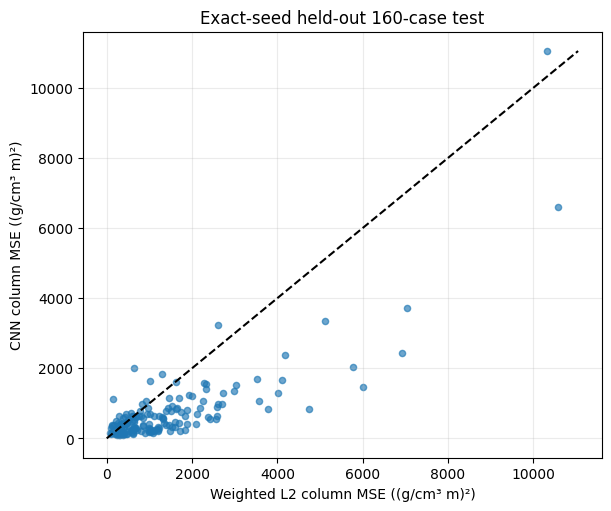

In [12]:
# Compare every held-out CNN case with the same-input weighted L2 result.
fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
ax.scatter(classical_mse, cnn_mse_physical, s=20, alpha=0.65)
lim = max(float(classical_mse.max()), float(cnn_mse_physical.max()))
ax.plot([0, lim], [0, lim], "k--")
ax.set(
    xlabel="Weighted L2 column MSE ((g/cm³ m)²)",
    ylabel="CNN column MSE ((g/cm³ m)²)",
    title="Exact-seed held-out 160-case test",
)
ax.grid(alpha=0.25)
plt.show()


### Plot ID and OOD score distributions

The fixed threshold is selected from separate in-distribution calibration data. Overlap between ID and OOD scores explains missed detections; the histogram is a diagnostic of this receipt, not a proposed new threshold. Preserve the recorded false-negative count when interpreting it.


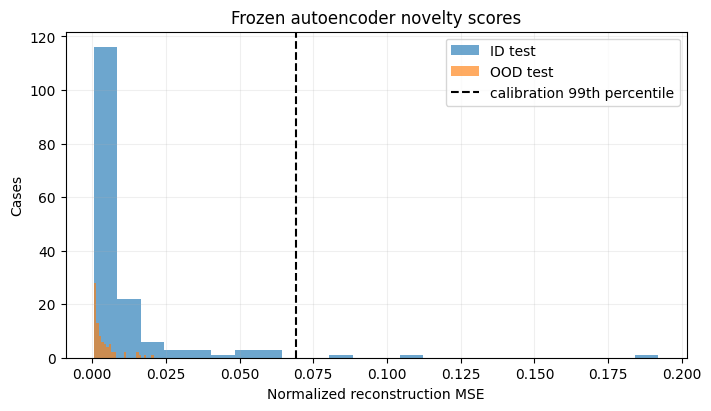

In [13]:
# Show the fixed reconstruction threshold against ID test and OOD scores.
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.hist(score_id, bins=24, alpha=0.65, label="ID test")
ax.hist(score_ood, bins=24, alpha=0.65, label="OOD test")
ax.axvline(threshold, color="black", ls="--", label="calibration 99th percentile")
ax.set(xlabel="Normalized reconstruction MSE", ylabel="Cases", title="Frozen autoencoder novelty scores")
ax.legend()
ax.grid(alpha=0.2)
plt.show()


### Figure interpretation

The fixed threshold separates some in-distribution scores but overlaps the OOD distribution heavily. It misses all 80 OOD cases while producing three false alarms among 160 in-distribution cases, consistent with TP/FN/FP/TN = 0/80/3/157. This histogram diagnoses the declared generator only and does not justify post-hoc threshold tuning.

### Reload the CNN through the checkpoint API

The bundle loader already verifies metadata and hashes. This independent public loader call reconstructs the CNN architecture from the ledger shape and reads the exact checkpoint path again; parameter equality confirms that inference did not rely on a modified in-memory model.


In [14]:
# Reload the frozen CNN and compare parameters with the model used above.
cnn_entry = training_meta["models"]["cnn"]
cnn_path = root / "data/derived/v2/models" / Path(cnn_entry["checkpoint"]).name
cnn_reloaded = learning.load_checkpoint(
    learning.InverseCNN(input_shape=tuple(training_meta["survey_shape"])), cnn_path
).to(next(cnn_model.parameters()).device)
cnn_reload_error = max(
    float((left - right).abs().max().detach().cpu())
    for left, right in zip(cnn_model.parameters(), cnn_reloaded.parameters(), strict=True)
)
assert cnn_reload_error == 0.0
print("CNN parameter reload maximum difference", cnn_reload_error)


CNN parameter reload maximum difference 0.0


### Quantify the reconstructed held-out column in physical units

Apply the repository's recovery metric to the exact inferred and integrated-truth arrays. Its RMSE and zero-start ratio summarize the column target only; the CNN does not output a depth-resolved density volume.


In [15]:
# Apply the shared physical model metric to the exact held-out inference.
from evaluation import model_metrics

physical_prediction = pred_test * training_meta["target_scale"]
physical_truth = y_test * training_meta["target_scale"]
heldout_recovery = model_metrics(physical_prediction, physical_truth)
print("physical column RMSE", heldout_recovery["model_rmse"])
print("baseline ratio", heldout_recovery["baseline_ratio"])


physical column RMSE 27.491026845187832
baseline ratio 0.36162633287599516
